# Машинное обучение

# Тема 6. Линейная регрессия

In [52]:
import pandas as pd
import numpy as np   
import matplotlib.pyplot as plt  
import seaborn as sns
from scipy import stats
import itertools
import math
from sklearn.linear_model import LinearRegression  # модель линейной регрессии
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # масштабирование и кодирование признаков
from sklearn.model_selection import train_test_split, cross_val_score, KFold
# разделение данных на обучающую/тестовую выборки и кросс-валидация
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error  # метрики качества регрессии
from statsmodels.stats.outliers_influence import variance_inflation_factor  # диагностика мультиколлинеарности
from statsmodels.stats.stattools import durbin_watson  # проверка автокорреляции остатков
import statsmodels.api as sm  # регрессия для статистики и эконометрики
from sklearn.compose import ColumnTransformer  # преобразование признаков
from sklearn.pipeline import Pipeline  # конвеер обработки данных
from statsmodels.stats.diagnostic import het_breuschpagan  # проверка гетероскедастичности
import warnings
warnings.filterwarnings('ignore')

### [Текучесть кадров и производительность труда](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

[Описание признаков](https://inseaddataanalytics.github.io/INSEADAnalytics/groupprojects/January2018FBL/IBM_Attrition_VSS.html)

| Имя признака                   | Описание признака                                     |
|------------------------|------------------------------------------------|
| Age                    | Numerical Value                                 |
| Attrition              | Employee leaving the company (0=no, 1=yes)     |
| BusinessTravel        | (1=No Travel, 2=Travel Frequently, 3=Travel Rarely) |
| DailyRate             | Numerical Value - Salary Level                  |
| Department             | (1=HR, 2=R&D, 3=Sales)                         |
| DistanceFromHome     | Numerical Value - THE DISTANCE FROM WORK TO HOME |
| Education              | Numerical Value                                 |
| EducationField        | (1=HR, 2=LIFE SCIENCES, 3=MARKETING, 4=MEDICAL SCIENCES, 5=OTHERS, 6=TECHNICAL) |
| EmployeeCount         | Numerical Value                                 |
| EmployeeNumber        | Numerical Value - EMPLOYEE ID                   |
| EnvironmentSatisfaction| Numerical Value - SATISFACTION WITH THE ENVIRONMENT |
| Gender                 | (1=FEMALE, 2=MALE)                             |
| HourlyRate| Numerical Value - HOURLY SALARY                 |
| JobInvolvement        | Numerical Value - JOB INVOLVEMENT                |
| JobLevel              | Numerical Value - LEVEL OF JOB                   |
| JobRole               | (1=HC REP, 2=HR, 3=LAB TECHNICIAN, 4=MANAGER, 5=MANAGING DIRECTOR, 6=RESEARCH DIRECTOR, 7=RESEARCH SCIENTIST, 8=SALES EXECUTIVE, 9=SALES REPRESENTATIVE) |
| JobSatisfaction       | Numerical Value - SATISFACTION WITH THE JOB     |
| MaritalStatus         | (1=DIVORCED, 2=MARRIED, 3=SINGLE)               |
| MonthlyIncome         | Numerical Value - MONTHLY SALARY                 |
| MonthlyRate            | Numerical Value - MONTHLY RATE                   |
| NumCompaniesWorked    | Numerical Value - NO. OF COMPANIES WORKED AT    |
| Over18                | (1=YES, 2=NO)                                   |
| OverTime               | (1=NO, 2=YES)                                   |
| PercentSalaryHike    | Numerical Value - PERCENTAGE INCREASE IN SALARY |
| PerformanceRating     | Numerical Value - PERFORMANCE RATING             |
| RelationshipSatisfaction | Numerical Value - RELATIONS SATISFACTION         |
| StandardHours         | Numerical Value - STANDARD HOURS                  |
| StockOptionLevel    | Numerical Value - STOCK OPTIONS                   |
| TotalWorkingYears    | Numerical Value - TOTAL YEARS WORKED              |
| TrainingTimesLastYear| Numerical Value - HOURS SPENT TRAINING           |
| WorkLifeBalance      | Numerical Value - TIME SPENT BETWEEN WORK AND OUTSIDE |
| YearsAtCompany       | Numerical Value - TOTAL NUMBER OF YEARS AT THE COMPANY |
| YearsInCurrentRole  | Numerical Value - YEARS IN CURRENT ROLE           |
| YearsSinceLastPromotion | Numerical Value - LAST PROMOTION               |
| YearsWithCurrManager  | Numerical Value - YEARS SPENT WITH CURRENT MANAGER |


In [6]:
df = pd.read_csv("Employee_Attrition.csv")
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

Сгруппируем переменные по типам данных.

In [8]:
for t in df.dtypes.unique():
     print('Тип: {}\n{}\n'.format(t, df.dtypes[df.dtypes==t].index.values))

Тип: int64
['Age' 'DailyRate' 'DistanceFromHome' 'Education' 'EmployeeCount'
 'EmployeeNumber' 'EnvironmentSatisfaction' 'HourlyRate' 'JobInvolvement'
 'JobLevel' 'JobSatisfaction' 'MonthlyIncome' 'MonthlyRate'
 'NumCompaniesWorked' 'PercentSalaryHike' 'PerformanceRating'
 'RelationshipSatisfaction' 'StandardHours' 'StockOptionLevel'
 'TotalWorkingYears' 'TrainingTimesLastYear' 'WorkLifeBalance'
 'YearsAtCompany' 'YearsInCurrentRole' 'YearsSinceLastPromotion'
 'YearsWithCurrManager']

Тип: object
['Attrition' 'BusinessTravel' 'Department' 'EducationField' 'Gender'
 'JobRole' 'MaritalStatus' 'Over18' 'OverTime']



### Целевая переменная: ежемесячная зарплата

In [9]:
df['MonthlyIncome'].describe()

count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

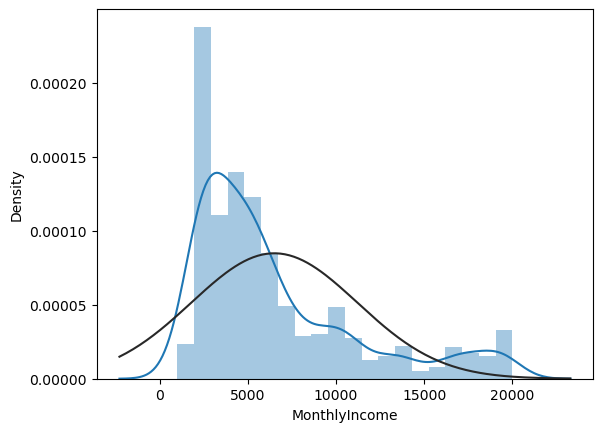

In [10]:
sns.distplot(df.MonthlyIncome, fit=stats.norm);

In [11]:
print('Асимметрия (Skewness): {:.4f}'.format(df['MonthlyIncome'].skew()))
print('Эксцесс (Kurtosis): {:.4f}'.format(df['MonthlyIncome'].kurt()))
print('Межквартильная широта: {:.4f}'.format((df['MonthlyIncome'].quantile(0.75) - df['MonthlyIncome'].quantile(0.25))/2))
print('Децильное отношение: {:.4f}'.format(df['MonthlyIncome'].quantile(0.9)/df['MonthlyIncome'].quantile(0.1)))

Асимметрия (Skewness): 1.3698
Эксцесс (Kurtosis): 1.0052
Межквартильная широта: 2734.0000
Децильное отношение: 5.9439


In [12]:
stats.kstest(df.MonthlyIncome, 'norm', args=(df.MonthlyIncome.mean(), df.MonthlyIncome.std()))

KstestResult(statistic=np.float64(0.16892145497691968), pvalue=np.float64(3.88275968028508e-37), statistic_location=np.int64(5775), statistic_sign=np.int8(1))

Целевая переменная имеет распределение отличное от нормального. Оно асимметрично (сдвиг в сторону меньших значений) и характеризуется пиковостью. Среднее значение - 6502.9, стандартное отклонение довольно высокое - 4708.0. Медиана  - 4919, межквартильная широта - 2734, что также характеризует довольно большой разброс серединных 50% значений относительно медианы. Децильное отношение - 5.9 подтверждает сильную вариативность между крайними значениями. Тест Колмогорова-Смирнова (p < 0.05) подтверждает статистическое отклонение от нормальности. Для нормализации данных можно попробовать применить логарифмическое преобразование.

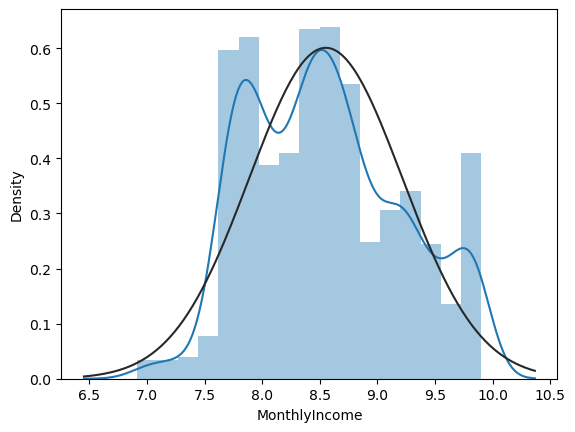

In [13]:
MonthlyIncome_log = np.log(df['MonthlyIncome'])  # натуральный логарифм
sns.distplot(MonthlyIncome_log, fit=stats.norm); 

Теперь распределение больше похоже на нормальное.

### Потенциальные предикторы

Рассмотрим какие предикторы могут влиять на зарплату.

**Карьерный путь и опыт**
- TotalWorkingYears
- YearsAtCompany
- YearsInCurrentRole
- YearsWithCurrManager
- YearsSinceLastPromotion
- NumCompaniesWorked

**Должность, уровень, отдел**
- JobLevel 
- JobRole
- Department

**Образование**
- Education
- EducationField

**Производительность и финансовое стимулирование**
- PerformanceRating
- PercentSalaryHike

**Рабочая нагрузка и обучение**
- OverTime
- BusinessTravel
- TrainingTimesLastYear

**Удовлетворенность, вовлеченность и баланс**
- EnvironmentSatisfaction
- BusinessTravel
- JobSatisfaction
- RelationshipSatisfaction
- JobInvolvement
- WorkLifeBalance

**Другое**
- DistanceFromHome
- StockOptionLevel

**Демография**
- Age
- Gender
- MaritalStatus

**ИСКЛЮЧАЕМ**

**Напрямую связаны с зарплатой и могут искусственно завысить качество модели** (утечка данных)
- DailyRate
- HourlyRate
- MonthlyRate

**ID, константы, увольнение**
- EmployeeNumber (ID)
- EmployeeCount (константа)
- Over18 (константа)
- StandardHours (константа)
- Attrition (может быть следствием зарплаты, а не причиной)

Удаляем ненужные признаки.

In [14]:
drop_cols = [
    "DailyRate",
    "HourlyRate",
    "MonthlyRate",
    "EmployeeNumber",
    "EmployeeCount",
    "StandardHours",
    "Over18",
    "Attrition"
]

df = df.drop(columns=drop_cols)

Разделяем признаки и целевую переменную.

In [15]:
X = df.drop(columns=["MonthlyIncome"])
y = df["MonthlyIncome"]

Определяем числовые и категориальные признаки.

In [16]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)

Числовые: Index(['Age', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction',
       'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'NumCompaniesWorked',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')
Категориальные: Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'OverTime'],
      dtype='object')


### Числовые признаки

Рассмотрим корреляцию между числовыми признаками.

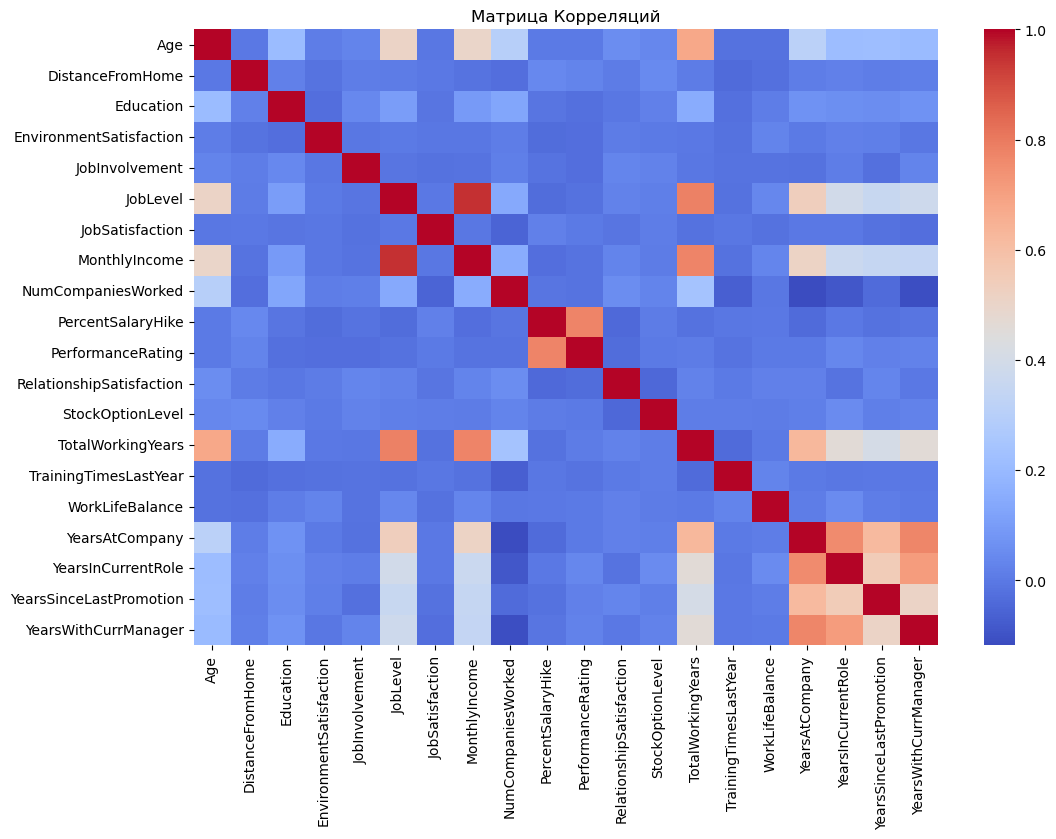

In [17]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap="coolwarm")
plt.title("Матрица Корреляций")
plt.show()

Между некоторыми признаками есть сильные корреляции, что может стать причиной мультиколлинеарности. Выведем признаки, между которыми корреляция больше 0.65.

In [18]:
corr_matrix = df[numeric_features].corr()

pairs = []
for i, j in itertools.combinations(corr_matrix.columns, 2):
    corr = corr_matrix.loc[i, j]
    if abs(corr) > 0.65:
        pairs.append((i, j, corr))

for p in pairs:
    print(p)

('Age', 'TotalWorkingYears', np.float64(0.6803805357911984))
('JobLevel', 'TotalWorkingYears', np.float64(0.7822078045362748))
('PercentSalaryHike', 'PerformanceRating', np.float64(0.7735499964012669))
('YearsAtCompany', 'YearsInCurrentRole', np.float64(0.7587537366134618))
('YearsAtCompany', 'YearsWithCurrManager', np.float64(0.7692124251007031))
('YearsInCurrentRole', 'YearsWithCurrManager', np.float64(0.7143647616385931))


**Удалим:**
- JobLevel
- PercentSalaryHike
- YearsInCurrentRole
- YearsWithCurrManager
- Age

**Оставим:**
- TotalWorkingYears — более фундаментальный показатель опыта
- PerformanceRating — более интерпретируемая метрика производительности
- YearsAtCompany — базовая переменная стажа внутри компании

In [19]:
cols_to_drop = [
    'JobLevel',
    'PercentSalaryHike',
    'YearsInCurrentRole',
    'YearsWithCurrManager',
    'Age'
]

X = X.drop(columns=cols_to_drop)
numeric_features = [col for col in numeric_features if col not in cols_to_drop]

In [20]:
corr_matrix = df[numeric_features].corr()

pairs = []
for i, j in itertools.combinations(corr_matrix.columns, 2):
    corr = corr_matrix.loc[i, j]
    if abs(corr) > 0.65:
        pairs.append((i, j, corr))

for p in pairs:
    print(p)

Теперь между признаками нет корреляций больше 0.65.

Проверим VIF.

In [21]:
vif = pd.DataFrame()
vif["feature"] = df[numeric_features].columns
vif["VIF"] = [variance_inflation_factor(df[numeric_features].values, i) for i in range(df[numeric_features].shape[1])]

vif = vif.sort_values(by="VIF", ascending=False).reset_index(drop=True)
print(vif)

                     feature        VIF
0          PerformanceRating  34.771633
1            WorkLifeBalance  14.770186
2             JobInvolvement  14.096601
3                  Education   8.952835
4   RelationshipSatisfaction   7.044253
5    EnvironmentSatisfaction   6.848371
6            JobSatisfaction   6.793172
7          TotalWorkingYears   6.177197
8             YearsAtCompany   5.773965
9      TrainingTimesLastYear   5.525747
10        NumCompaniesWorked   2.661353
11   YearsSinceLastPromotion   2.374852
12          DistanceFromHome   2.286939
13          StockOptionLevel   1.875666


VIF больше 10 у 3-ех признаков. То есть некоторые признаки почти линейно объясняются другими, хотя высоких парных корреляций не осталось.

Посмотрим как эти три признаки коррелируют с зарплатой.

In [22]:
corr = df[['PerformanceRating', 'WorkLifeBalance', 'JobInvolvement', 'MonthlyIncome']].corr()
print(corr['MonthlyIncome'].drop('MonthlyIncome'))

PerformanceRating   -0.017120
WorkLifeBalance      0.030683
JobInvolvement      -0.015271
Name: MonthlyIncome, dtype: float64


Корреляции почти нулевые, можно признаки удалить.

In [23]:
cols_to_drop = [
    'PerformanceRating', 
    'WorkLifeBalance', 
    'JobInvolvement'
]

X = X.drop(columns=cols_to_drop)
numeric_features = [col for col in numeric_features if col not in cols_to_drop]

In [24]:
vif = pd.DataFrame()
vif["feature"] = df[numeric_features].columns
vif["VIF"] = [variance_inflation_factor(df[numeric_features].values, i) for i in range(df[numeric_features].shape[1])]

vif = vif.sort_values(by="VIF", ascending=False).reset_index(drop=True)
print(vif)

                     feature       VIF
0                  Education  7.570109
1          TotalWorkingYears  6.158279
2   RelationshipSatisfaction  6.138471
3    EnvironmentSatisfaction  5.915438
4            JobSatisfaction  5.863329
5             YearsAtCompany  5.747807
6      TrainingTimesLastYear  4.887818
7         NumCompaniesWorked  2.634434
8    YearsSinceLastPromotion  2.372549
9           DistanceFromHome  2.215580
10          StockOptionLevel  1.846105


Больше нет проблемы мультиколлинеарности, работа с подготовкой числовых признаков завершена.

### Категориальные признаки

Выведем частотные таблицы.

In [25]:
for col in categorical_features:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False)) 
    print("\n")

--- BusinessTravel ---
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64


--- Department ---
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64


--- EducationField ---
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64


--- Gender ---
Gender
Male      882
Female    588
Name: count, dtype: int64


--- JobRole ---
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64


--- MaritalStatus ---
MaritalStatus
Married     673
Single      470
Div

По категориальным предикторам все группы достаточно наполнены. Объединять или удалять группы не стоит. 

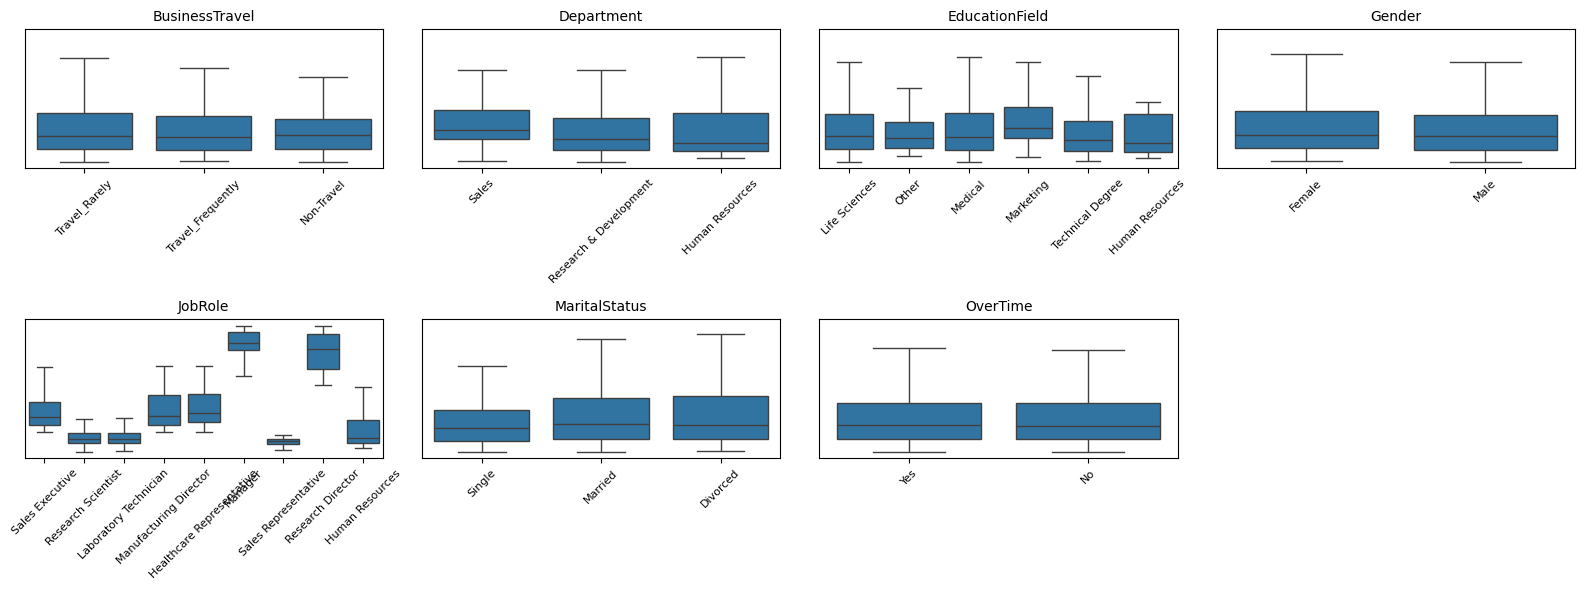

In [26]:
n_cols = math.ceil(len(categorical_features) / 2)
fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 6), sharey=True)
axes = axes.flatten()

for ax, cat in zip(axes, categorical_features):
    sns.boxplot(x=cat, y=y, data=df, ax=ax, showfliers=False) 
    ax.set_title(cat, fontsize=10)  
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', left=False, labelleft=False)

for i in range(len(categorical_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

На графиках видны отличия зарплаты по некоторым категориям.

Используем One-Hot Encoding для кодирования категориальных признаков.

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first"), categorical_features)
    ],
    remainder="passthrough"
)

`drop="first"` убирает первый бинарный столбец при one-hot кодировании. Это нужно, чтобы избежать мультиколлинеарности (dummy trap).

Создаем Pipeline

In [28]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),  # препроцессинг
        ("regressor", LinearRegression())  # обучение модели
    ]
)

Делим данные на train и test.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [30]:
X_test.columns

Index(['BusinessTravel', 'Department', 'DistanceFromHome', 'Education',
       'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobRole',
       'JobSatisfaction', 'MaritalStatus', 'NumCompaniesWorked', 'OverTime',
       'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears',
       'TrainingTimesLastYear', 'YearsAtCompany', 'YearsSinceLastPromotion'],
      dtype='object')

Обучаем модель

In [31]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Предсказываем значения на тестовой выборке.

In [32]:
y_pred = model.predict(X_test)

Оцениваем качество модели.

In [33]:
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"R2: {r2:.3f}, RMSE: {rmse:.2f}, MAE: {mae:.2f}")

R2: 0.869, RMSE: 1689.38, MAE: 1334.78


In [34]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2")

rmse_scores = np.sqrt(-cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_mean_squared_error"))
mae_scores = -cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_mean_absolute_error")

print("Результаты кросс-валидации:")
print(f"Средний R2: {r2_scores.mean():.3f}")
print(f"Средний RMSE: {rmse_scores.mean():.2f}")
print(f"Средний MAE: {mae_scores.mean():.2f}")

Результаты кросс-валидации:
Средний R2: 0.869
Средний RMSE: 1692.86
Средний MAE: 1320.94


Качество модели хорошее. Кросс-валидация подтвердила стабильность модели и отсутствие значительного переобучения. Можно сделать вывод, что модель обладает хорошей обобщающей способностью и может использоваться для прогнозирования целевой переменной с приемлемой точностью.

Визуализируем предсказания.

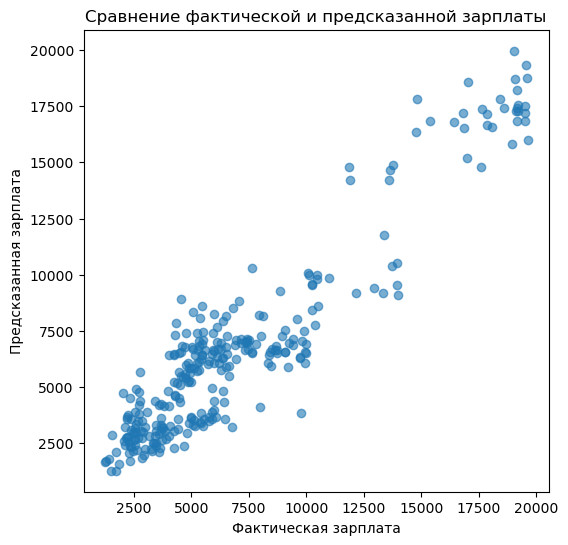

In [35]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Фактическая зарплата")
plt.ylabel("Предсказанная зарплата")

plt.title("Сравнение фактической и предсказанной зарплаты")

plt.show()

Высокая корреляция предсказаний с фактическими зарплатами.

Рассмотрим коэффициенты модели.

In [36]:
ohe = model.named_steps["preprocessor"].named_transformers_["cat"]

encoded_cat = ohe.get_feature_names_out(categorical_features)

all_features = np.concatenate([encoded_cat, numeric_features])

In [37]:
coefficients = model.named_steps["regressor"].coef_

coef_df = pd.DataFrame({
    "признак": all_features,
    "коэффициент": coefficients
})

Топ-10 факторов увеличения зарплаты.

In [38]:
coef_df.sort_values(by="коэффициент", ascending=False).head(10)

,признак,коэффициент
12,JobRole_Manager,7862.739856
14,JobRole_Research Director,7101.641029
16,JobRole_Sales Executive,777.002090
0,BusinessTravel_Travel_Frequently,279.594369
2,Department_Research & Development,257.124088
1,BusinessTravel_Travel_Rarely,196.797678
28,TotalWorkingYears,183.834529
9,Gender_Male,127.188295
20,OverTime_Yes,100.336134
13,JobRole_Manufacturing Director,79.893620


Топ-10 факторов снижения зарплаты.

In [39]:
coef_df.sort_values(by="коэффициент").head(10)

,признак,коэффициент
15,JobRole_Research Scientist,-3068.696702
11,JobRole_Laboratory Technician,-2988.850378
17,JobRole_Sales Representative,-2278.923555
10,JobRole_Human Resources,-2124.781312
3,Department_Sales,-468.186563
7,EducationField_Other,-344.466501
6,EducationField_Medical,-239.946703
5,EducationField_Marketing,-228.269207
4,EducationField_Life Sciences,-213.546239
22,Education,-64.383774


Выведем статистическую значимость коэффициентов регрессии.

In [40]:
X_transformed = model.named_steps['preprocessor'].transform(X_train)

cat_features = model.named_steps['preprocessor'] \
    .named_transformers_['cat'] \
    .get_feature_names_out(categorical_features)

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
feature_names = ["const"] + list(feature_names)

X_sm = sm.add_constant(X_transformed)

model_sm = sm.OLS(y_train, X_sm).fit()

results_df = pd.DataFrame({
    'признак': feature_names,
    'коэффициент': model_sm.params.round(4),
    'p-value': model_sm.pvalues.round(4)
})

pd.set_option('display.float_format', '{:.4f}'.format)
print(results_df)

                                      признак  коэффициент  p-value
const                                   const    4594.7965   0.0000
x1      cat__BusinessTravel_Travel_Frequently     279.5944   0.1483
x2          cat__BusinessTravel_Travel_Rarely     196.7977   0.2454
x3     cat__Department_Research & Development     257.1241   0.7108
x4                      cat__Department_Sales    -468.1866   0.5068
x5          cat__EducationField_Life Sciences    -213.5462   0.6554
x6              cat__EducationField_Marketing    -228.2692   0.6543
x7                cat__EducationField_Medical    -239.9467   0.6164
x8                  cat__EducationField_Other    -344.4665   0.5021
x9       cat__EducationField_Technical Degree     -62.9344   0.9003
x10                          cat__Gender_Male     127.1883   0.2040
x11              cat__JobRole_Human Resources   -2124.7813   0.0035
x12        cat__JobRole_Laboratory Technician   -2988.8504   0.0000
x13                      cat__JobRole_Manager   

Не все признаки оказывают статистически значимое влияние на зарплату. Значимыми являются признаки, коэффициенты которых имеют p-value < 0.05.

Если цель исследования - выявить исключительно те факторы, которые  реально влияют на зарплату, то незначимые коэффициенты лучше убрать.

Если цель - предсказание, то незначимые коэффициенты можно оставить, особенно если модель построена для максимального качества предсказаний, а не интерпретации.


Выведем референтные группы для категориальных признаков.

In [41]:
for col in categorical_features:
    categories = df[col].unique()
    ref = sorted(categories)[0]  
    print(f"Признак: {col}, референтная группа: {ref}")

Признак: BusinessTravel, референтная группа: Non-Travel
Признак: Department, референтная группа: Human Resources
Признак: EducationField, референтная группа: Human Resources
Признак: Gender, референтная группа: Female
Признак: JobRole, референтная группа: Healthcare Representative
Признак: MaritalStatus, референтная группа: Divorced
Признак: OverTime, референтная группа: No


### Интерпретация коэффициентов

- Каждый дополнительный год общего стажа работы (TotalWorkingYears) увеличивает ожидаемую зарплату примерно на 183.8 единицы, при прочих равных условиях. То есть, если сотрудник имеет на 1 год больше опыта, модель ожидает, что его зарплата будет выше примерно на 183.8 единицы.
- Сотрудник с должностью Manager в среднем зарабатывает на 7862.7 единицы больше, чем сотрудник с должностью Healthcare Representative (референтная группа), при прочих равных условиях.

_Далее интерпретируйте остальные коэффициенты модели..._

Чтобы можно было сравнить предикторы по степени влияния на целевую переменную, нужно стандартизировать значения всех признаков в модели.

In [43]:
X_transformed = model.named_steps["preprocessor"].transform(X_train)
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

y = y_train.to_numpy() if hasattr(y_train, "to_numpy") else y_train

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)

X_sm = sm.add_constant(X_scaled)

model_sm = sm.OLS(y, X_sm).fit()

results_df = pd.DataFrame({
    "feature": ["const"] + list(feature_names),
    "coef": model_sm.params.round(4),
    "p_value": model_sm.pvalues.round(4)
})

results_df["abs_coef"] = results_df["coef"].abs()

results_df = results_df.sort_values(
    "abs_coef",
    ascending=False
)

print(results_df)

                                   feature       coef  p_value  abs_coef
0                                    const  6382.5238   0.0000 6382.5238
13                    cat__JobRole_Manager  1968.2644   0.0000 1968.2644
15          cat__JobRole_Research Director  1657.5847   0.0000 1657.5847
29            remainder__TotalWorkingYears  1436.0471   0.0000 1436.0471
16         cat__JobRole_Research Scientist -1240.5885   0.0000 1240.5885
12      cat__JobRole_Laboratory Technician -1131.7358   0.0000 1131.7358
18       cat__JobRole_Sales Representative  -556.8609   0.0000  556.8609
11            cat__JobRole_Human Resources  -394.3103   0.0035  394.3103
17            cat__JobRole_Sales Executive   319.7402   0.0806  319.7402
4                    cat__Department_Sales  -215.9454   0.5068  215.9454
32      remainder__YearsSinceLastPromotion   131.9532   0.0321  131.9532
3   cat__Department_Research & Development   122.5990   0.7108  122.5990
7              cat__EducationField_Medical  -111.34

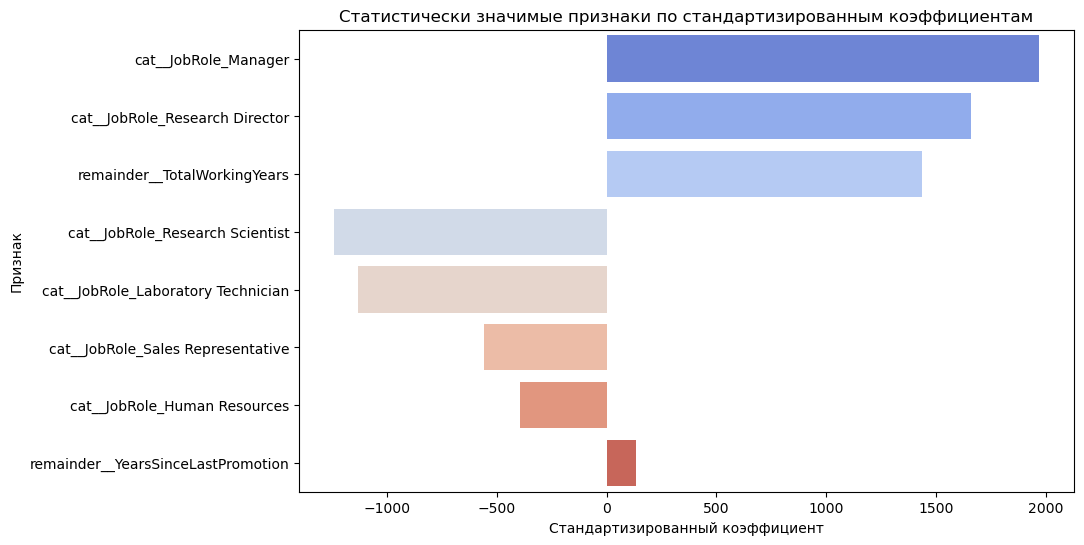

In [44]:
# убираем константу и оставляем только статистически значимые признаки
results_no_const = results_df[
    (results_df['feature'] != 'const') & 
    (results_df['p_value'] < 0.05)
]

# сортируем по абсолютному значению коэффициента
results_no_const = results_no_const.reindex(
    results_no_const['coef'].abs().sort_values(ascending=False).index
)

plt.figure(figsize=(10,6))
sns.barplot(
    x='coef',
    y='feature',
    data=results_no_const,
    palette='coolwarm'
)
plt.title("Статистически значимые признаки по стандартизированным коэффициентам")
plt.xlabel("Стандартизированный коэффициент")
plt.ylabel("Признак")
plt.show()

Интерпретация стандартизированных коэффициентов:

- Для числовых признаков: коэффициент показывает, на сколько изменяется  MonthlyIncome при увеличении соответствующего признака на одно стандартное отклонение, при прочих равных условиях.
- Для дамми: коэффициент отражает разницу в значении MonthlyIncome относительно референтной (базовой) категории.

Проверим остатки.

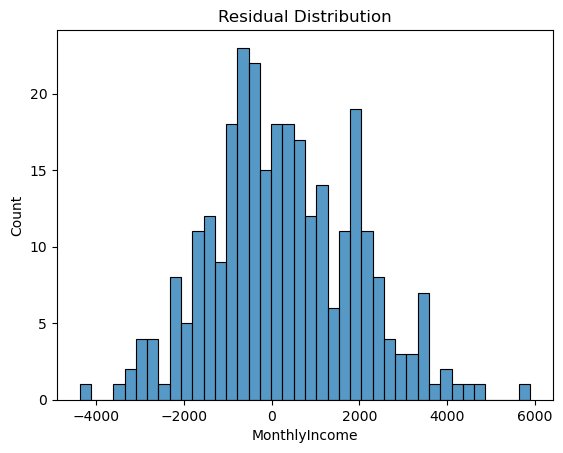

In [45]:
residuals = y_test - y_pred

sns.histplot(residuals, bins=40)
plt.title("Residual Distribution")
plt.show()

In [46]:
residuals_std = (residuals - np.mean(residuals)) / np.std(residuals)
ks_stat, p_value = stats.kstest(residuals_std, 'norm')

print(f"Тест Колмогорова-Смирнова (p-value): {p_value}")

Тест Колмогорова-Смирнова (p-value): 0.44931766447925314


Остатки имеют нормальное распределение.

Построим график зависимости остатков и предсказанных значений.

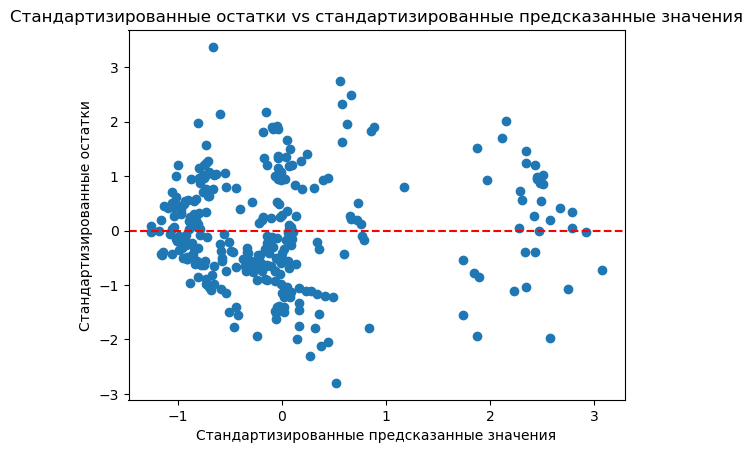

In [47]:
# стандартизируем предсказанные значения и остатки
y_pred_std = (y_pred - np.mean(y_pred)) / np.std(y_pred)
residuals_std = (residuals - np.mean(residuals)) / np.std(residuals)

plt.scatter(y_pred_std, residuals_std)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Стандартизированные предсказанные значения")
plt.ylabel("Стандартизированные остатки")
plt.title("Стандартизированные остатки vs стандартизированные предсказанные значения")
plt.show()

Нет тренда по предсказанным значениям → гомоскедастичность.

Проверим мультиколлинеарность

In [48]:
X_encoded = preprocessor.fit_transform(X)
X_encoded_df = pd.DataFrame(X_encoded, columns=all_features)

vif_data = pd.DataFrame()
vif_data['feature'] = X_encoded_df.columns
vif_data['VIF'] = [variance_inflation_factor(X_encoded_df.values, i) for i in range(X_encoded_df.shape[1])]
vif_data.sort_values('VIF', ascending=False).head(15)

,feature,VIF
2,Department_Research & Development,74.3468
3,Department_Sales,47.4308
4,EducationField_Life Sciences,37.6618
6,EducationField_Medical,29.1267
16,JobRole_Sales Executive,17.2209
5,EducationField_Marketing,11.3756
22,Education,9.2438
8,EducationField_Technical Degree,8.9949
28,TotalWorkingYears,8.5906
1,BusinessTravel_Travel_Rarely,7.9132


VIF > 10 → сильная мультиколлинеарность между дамми-переменными. Можно предположить, что образование связано с работой в определенных департаментах и на определенных ролях. Возможно, стоит удалить признак образование.

Выведем выбросы.

In [49]:
standard_resid = (residuals - np.mean(residuals)) / np.std(residuals)
outlier_values = standard_resid[np.abs(standard_resid) > 3]

print("Значения стандартизированных остатков больше 3 по модулю:")
print(outlier_values)

Значения стандартизированных остатков больше 3 по модулю:
1243   3.3717
Name: MonthlyIncome, dtype: float64


Есть один объект, но значение стандартизированного остатка не слишком высокое. Можно сделать вывод, что нет явной проблемы наличия выбросов.

Выведем влияющие наблюдения.

In [50]:
influence = model_sm.get_influence()

influence_df = pd.DataFrame({
    'leverage': influence.hat_matrix_diag,   
    'dffits': influence.dffits[0],           
    'cooks_distance': influence.cooks_distance[0] 
})

# пороговые значения
n, k = X_sm.shape
mean_leverage = k / n  
dffits_threshold = 2 * np.sqrt(k / n)
cooks_threshold = 1  

very_dangerous = influence_df[
    (influence_df['cooks_distance'] > cooks_threshold) &
    (influence_df['leverage'] > 3 * mean_leverage) &
    (np.abs(influence_df['dffits']) > dffits_threshold)
]

count_very_dangerous = very_dangerous.shape[0]
print(f"Количество потенциально опасных наблюдений: {count_very_dangerous}")

Количество потенциально опасных наблюдений: 0


Отбираем потенциально опасные влияющие наблюдения по трём строгим критериям: 
- Cook's distance > 1 (наблюдение сильно влияет на все коэффициенты модели), 
- leverage > 3 средних значений (наблюдение резко выделяется по комбинации признаков),
- |DFFITS| > 2√((k+1)/n) (наблюдение существенно меняет свои предсказания при исключении из модели).

Все три условия вместе гарантируют, что выбранные точки действительно могут сильно исказить модель и требуют особого внимания.

Опасных влияющих наблюдений нет.

Возможные улучшения модели:
- логарифмировать зарплату,
- устранить мультиколлинеарность категориальных признаков,
- добавить эффекты взаимодействия,
- добавить новые признаки по итогам проведения инженерии признаков.

### Задание на семинаре

Проведите улучшение модели. Прологарифмируйте целевую переменную, устраните мультиколлинеарность категориальных признаков, удалите статистически незначимые признаки, добавьте хотя бы один эффект взаимодействия. Сравните метрики улучшенной модели с полученными ранее. Как изменилась важность признаков?

In [47]:
# здесь написать ответ